# System Capacity & Care Load Analytics for Unaccompanied Children
**HHS Unaccompanied Alien Children (UAC) Program · Daily data, Jan 2023 – Dec 2025**

This notebook covers the full forecasting-methodology workflow from the project brief:

| Step | Section |
|---|---|
| 1 | Data ingestion & structuring |
| 2 | Data quality & validation |
| 3 | Derived healthcare capacity metrics |
| 4 | Trend & temporal analysis |
| 5 | Pressure & stress identification |
| 6 | Key Performance Indicators (KPIs) |
| 7 | Insights, recommendations & export for the Streamlit app |

**How to run:** put `HHS_Unaccompanied_Alien_Children_Program.csv` in the same folder as this notebook, then *Kernel → Restart & Run All*.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

CSV_PATH = "HHS_Unaccompanied_Alien_Children_Program.csv"
os.makedirs("figures", exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

## 0. Helper functions
All data-cleaning and metric logic lives in this one cell (the Streamlit app uses the identical code, so notebook and dashboard always agree).

**Metric definitions used throughout**

| Metric | Definition |
|---|---|
| Total System Load | `CBP custody + HHS care` |
| Net Daily Intake | `Transferred into HHS − Discharged from HHS` |
| Care Load Growth Rate | Day-over-day % change of Total System Load |
| Backlog Indicator | 7-day average net intake > 0, sustained for ≥ 7 consecutive days |
| Strain window | 14-day avg total load ≥ 75th percentile of the whole period, for ≥ 14 consecutive days |
| Relief window | 7-day avg total load falling week-over-week, for ≥ 7 consecutive days |
| Care Load Volatility Index | Std. deviation of the daily growth rate (% points) |
| Discharge Offset Ratio | `Σ discharged ÷ Σ transferred` (>1 means discharges outpace new transfers) |
| Backlog Accumulation Rate | Average net intake (children/day) during sustained-backlog days |

In [2]:
import numpy as np
import pandas as pd

# ----------------------------------------------------------------------
# 1. CONSTANTS
# ----------------------------------------------------------------------
RENAME = {
    "Date": "date",
    "Children apprehended and placed in CBP custody*": "apprehended",
    "Children in CBP custody": "cbp_custody",
    "Children transferred out of CBP custody": "transferred",
    "Children in HHS Care": "hhs_care",
    "Children discharged from HHS Care": "discharged",
}
STOCKS = ["cbp_custody", "hhs_care"]                      # "how many are in care today"
FLOWS = ["apprehended", "transferred", "discharged"]      # "how many moved today"

LABELS = {
    "cbp_custody": "Children in CBP custody",
    "hhs_care": "Children in HHS care",
    "total_load": "Total system load (CBP + HHS)",
    "apprehended": "Apprehended (intake)",
    "transferred": "Transferred CBP -> HHS",
    "discharged": "Discharged from HHS",
    "net_intake": "Net daily intake (transfers - discharges)",
    "growth_rate": "Care load growth rate (%)",
    "load_ma7": "Total load, 7-day avg",
    "load_ma14": "Total load, 14-day avg",
    "net_ma7": "Net intake, 7-day avg",
    "net_ma14": "Net intake, 14-day avg",
    "cum_net_intake": "Cumulative net intake (est.)",
}


# ----------------------------------------------------------------------
# 2. INGESTION
# ----------------------------------------------------------------------
def load_raw(src):
    """Read the HHS CSV and return (clean_dataframe, info_dict).

    Handles: blank trailing rows, the '*' in a column name, thousands
    separators in 'Children in HHS Care' ("2,484"), and 'Month DD, YYYY' dates.
    """
    df = pd.read_csv(src)
    df.columns = [str(c).strip() for c in df.columns]
    df = df.rename(columns=RENAME)
    missing_cols = set(RENAME.values()) - set(df.columns)
    if missing_cols:
        raise ValueError(f"CSV is missing expected columns: {sorted(missing_cols)}")
    df = df[list(RENAME.values())]

    n_total = len(df)
    df = df.dropna(how="all")
    n_blank = n_total - len(df)

    df["date"] = pd.to_datetime(df["date"], format="mixed", errors="coerce")
    for c in STOCKS + FLOWS:
        df[c] = pd.to_numeric(
            df[c].astype(str).str.replace(",", "", regex=False).str.strip(),
            errors="coerce",
        )
    n_bad_dates = int(df["date"].isna().sum())
    df = df.dropna(subset=["date"])
    info = {"rows_in_file": n_total, "blank_rows_dropped": n_blank,
            "unparseable_dates_dropped": n_bad_dates}
    return df, info


def build_daily(raw):
    """Sort, de-duplicate and reindex to a COMPLETE daily calendar.

    * Stock columns (census counts) are linearly interpolated across gaps.
    * Flow columns (daily movements) are left as NaN on unreported days --
      we never invent movements. `reported` marks real observations.
    """
    n_dups = int(raw["date"].duplicated().sum())
    df = raw.sort_values("date").drop_duplicates("date", keep="last").set_index("date")
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="D")
    d = df.reindex(full_idx)
    d.index.name = "date"
    d["reported"] = d.index.isin(df.index)
    d[STOCKS] = d[STOCKS].interpolate(method="time", limit_area="inside")
    d.attrs["duplicates_removed"] = n_dups
    return d


# ----------------------------------------------------------------------
# 3. VALIDATION
# ----------------------------------------------------------------------
def add_validation_flags(d):
    d = d.copy()
    d["flag_transfer_gt_cbp"] = d["transferred"] > d["cbp_custody"]
    d["flag_discharge_gt_hhs"] = d["discharged"] > d["hhs_care"]
    d["flag_negative"] = (d[STOCKS + FLOWS] < 0).any(axis=1)
    return d


def validation_summary(d, info=None):
    rep = d[d["reported"]]
    s = {
        "Date range": f"{d.index.min():%Y-%m-%d} to {d.index.max():%Y-%m-%d}",
        "Calendar days in range": len(d),
        "Days with a report": int(d["reported"].sum()),
        "Missing calendar days": int((~d["reported"]).sum()),
        "Reporting coverage (%)": round(100 * d["reported"].mean(), 1),
        "Duplicate dates removed": d.attrs.get("duplicates_removed", 0),
        "Transfers > CBP custody (days)": int(d["flag_transfer_gt_cbp"].sum()),
        "Discharges > HHS care (days)": int(d["flag_discharge_gt_hhs"].sum()),
        "Negative values (days)": int(d["flag_negative"].sum()),
        "Zero-intake reported days": int((rep["apprehended"] == 0).sum()),
    }
    if info:
        s["Blank rows dropped from file"] = info["blank_rows_dropped"]
    return pd.Series(s, name="value")


def reconciliation(d):
    """Does the change in HHS census match (transfers - discharges)?
    Uses only consecutive reported days."""
    r = d[d["reported"]].copy()
    gap = r.index.to_series().diff().dt.days
    r["census_change"] = r["hhs_care"].diff()
    r["net_flow"] = r["transferred"] - r["discharged"]
    r = r[gap == 1].dropna(subset=["census_change", "net_flow"])
    return {
        "pairs_compared": len(r),
        "correlation": float(r["census_change"].corr(r["net_flow"])),
        "mean_census_change": float(r["census_change"].mean()),
        "mean_net_flow": float(r["net_flow"].mean()),
    }


# ----------------------------------------------------------------------
# 4. DERIVED CAPACITY METRICS
# ----------------------------------------------------------------------
def run_len(mask):
    """For each True element, the total length of the consecutive-True run it
    belongs to (0 for False elements)."""
    mask = mask.fillna(False).astype(bool)
    grp = mask.ne(mask.shift(fill_value=False)).cumsum()
    return mask.astype(int).groupby(grp).transform("sum") * mask.astype(int)


def compute_metrics(d, strain_pct=75, min_strain_days=14, min_backlog_days=7):
    d = d.copy()

    # --- core metrics -------------------------------------------------
    d["total_load"] = d["cbp_custody"] + d["hhs_care"]
    d["net_intake"] = d["transferred"] - d["discharged"]
    d["growth_rate"] = d["total_load"].pct_change() * 100
    # estimate for gap days, used ONLY for the cumulative curve
    d["net_intake_est"] = (
        d["net_intake"].interpolate(method="time", limit_area="inside").fillna(0)
    )
    d["cum_net_intake"] = d["net_intake_est"].cumsum()

    # --- rolling windows ----------------------------------------------
    for w in (7, 14):
        d[f"load_ma{w}"] = d["total_load"].rolling(w, min_periods=1).mean()
        d[f"load_std{w}"] = d["total_load"].rolling(w, min_periods=2).std()
        d[f"net_ma{w}"] = d["net_intake"].rolling(w, min_periods=2).mean()
    d["load_cv14"] = 100 * d["load_std14"] / d["load_ma14"]
    d["growth_std14"] = d["growth_rate"].rolling(14, min_periods=5).std()

    # --- backlog indicator (sustained positive net intake) --------------
    d["backlog_day"] = d["net_ma7"] > 0
    d["backlog_run"] = run_len(d["backlog_day"])
    d["backlog_sustained"] = d["backlog_run"] >= min_backlog_days

    # --- supplementary: census-based build-up (complements net intake) --
    d["census_change"] = d["hhs_care"].diff()
    d["census_ma7"] = d["census_change"].rolling(7, min_periods=3).mean()
    d["census_buildup"] = run_len(d["census_ma7"] > 0) >= min_backlog_days

    # --- strain & relief -----------------------------------------------
    thr = d["total_load"].quantile(strain_pct / 100)
    d["strain_threshold"] = thr
    d["high_load"] = d["load_ma14"] >= thr
    d["strain_run"] = run_len(d["high_load"])
    d["strain_window"] = d["strain_run"] >= min_strain_days
    d["load_trend7"] = d["load_ma7"].diff(7)
    d["relief_day"] = d["load_trend7"] < 0
    d["relief_window"] = run_len(d["relief_day"]) >= 7
    d["status"] = np.select(
        [d["strain_window"] & ~d["relief_window"], d["relief_window"]],
        ["Strain", "Relief"],
        default="Stable",
    )

    # --- robust anomaly flag on daily change (MAD z-score) ---------------
    g = d["growth_rate"]
    mad = (g - g.median()).abs().median()
    d["flag_growth_outlier"] = ((g - g.median()).abs() / (1.4826 * mad)) > 3.5 if mad > 0 else False
    return d


def list_windows(d, flag):
    """Table of contiguous periods where boolean column `flag` is True."""
    m = d[flag].fillna(False).astype(bool)
    grp = m.ne(m.shift(fill_value=False)).cumsum()
    rows = []
    for _, seg in d[m].groupby(grp[m]):
        rows.append({
            "start": seg.index[0].date(), "end": seg.index[-1].date(),
            "days": len(seg),
            "avg_total_load": round(seg["total_load"].mean()),
            "peak_total_load": round(seg["total_load"].max()),
            "avg_net_intake": round(seg["net_intake"].mean(), 1),
        })
    return pd.DataFrame(rows)


# ----------------------------------------------------------------------
# 5. TIME GRANULARITY
# ----------------------------------------------------------------------
FREQ = {"Daily": "D", "Weekly": "W", "Monthly": "MS"}


def aggregate(d, freq="D"):
    """Resample to weekly/monthly. Stocks and flows are averaged (avg per
    day) so periods with different numbers of reported days stay comparable."""
    if freq == "D":
        return d
    cols = [c for c in ["cbp_custody", "hhs_care", "total_load", "apprehended",
                        "transferred", "discharged", "net_intake", "net_ma7",
                        "net_ma14", "load_ma7", "load_ma14"] if c in d.columns]
    out = d[cols].resample(freq).mean()
    out["cum_net_intake"] = d["cum_net_intake"].resample(freq).last()
    out["growth_rate"] = out["total_load"].pct_change() * 100
    out["strain_share"] = 100 * d["strain_window"].resample(freq).mean()
    out["backlog_share"] = 100 * d["backlog_sustained"].resample(freq).mean()
    out["census_change"] = d["census_change"].resample(freq).mean()
    return out


# ----------------------------------------------------------------------
# 6. KPIs
# ----------------------------------------------------------------------
def compute_kpis(d):
    nan = float("nan")
    if len(d) == 0:
        return {k: nan for k in ["total_latest", "total_avg", "peak_total",
                                 "net_pressure", "cum_net", "clvi",
                                 "backlog_rate", "backlog_share", "buildup_share", "dor"]}
    rep = d[d["reported"]]
    both = rep.dropna(subset=["transferred", "discharged"])
    sustained = d[d["backlog_sustained"]]
    return {
        "total_latest": d["total_load"].iloc[-1],
        "total_avg": d["total_load"].mean(),
        "peak_total": d["total_load"].max(),
        "peak_date": d["total_load"].idxmax(),
        "net_pressure": rep["net_intake"].mean(),
        "cum_net": d["net_intake_est"].sum(),
        "clvi": d["growth_rate"].std(),
        "backlog_rate": sustained["net_intake"].mean() if len(sustained) else 0.0,
        "backlog_share": 100 * d["backlog_sustained"].mean(),
        "buildup_share": 100 * d["census_buildup"].mean(),
        "dor": (both["discharged"].sum() / both["transferred"].sum())
        if both["transferred"].sum() > 0 else nan,
    }


def load_and_prepare(src, strain_pct=75):
    raw, info = load_raw(src)
    daily = build_daily(raw)
    daily = add_validation_flags(daily)
    daily = compute_metrics(daily, strain_pct=strain_pct)
    return daily, info

## 1. Data ingestion & structuring
Goals: load the CSV, convert `Date` to datetime, enforce chronological order and build a complete daily index.

Quirks found in the raw file (all handled in `load_raw`):
* ~450 completely blank rows at the bottom of the file
* `Children in HHS Care` is stored as **text** with thousands separators (`"2,484"`)
* One column header ends in an asterisk (`...CBP custody*`)
* Dates look like `December 21, 2025` and the file is in **reverse** chronological order
* Many calendar days (weekends/holidays) have no report at all

In [3]:
raw, info = load_raw(CSV_PATH)
print("Ingestion summary:", info)
print("\nShape after cleaning:", raw.shape)
raw.head()

Ingestion summary: {'rows_in_file': 1170, 'blank_rows_dropped': 450, 'unparseable_dates_dropped': 0}

Shape after cleaning: (720, 6)


,date,apprehended,cbp_custody,transferred,hhs_care,discharged
0,2025-12-21,6.0,18.0,11.0,2484,14.0
1,2025-12-18,11.0,50.0,6.0,2472,16.0
2,2025-12-17,7.0,31.0,11.0,2481,10.0
3,2025-12-16,8.0,54.0,15.0,2468,9.0
4,2025-12-15,11.0,42.0,9.0,2470,7.0


In [4]:
daily = build_daily(raw)          # sorted, de-duplicated, complete daily calendar
print("Chronological order OK:", daily.index.is_monotonic_increasing)
print("Index is a complete daily range:", (daily.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all())
print("Rows in complete daily index:", len(daily))
daily[["cbp_custody","hhs_care","apprehended","transferred","discharged","reported"]].head(10)

Chronological order OK: True
Index is a complete daily range: True
Rows in complete daily index: 1075


,cbp_custody,hhs_care,apprehended,transferred,discharged,reported
date,,,,,,
2023-01-12,53.0,6566.0,33.0,34.0,436.0,True
2023-01-13,52.6,6621.6,NaN,NaN,NaN,False
2023-01-14,52.2,6677.2,NaN,NaN,NaN,False
2023-01-15,51.8,6732.8,NaN,NaN,NaN,False
2023-01-16,51.4,6788.4,NaN,NaN,NaN,False
2023-01-17,51.0,6844.0,NaN,NaN,NaN,False
2023-01-18,50.6,6899.6,NaN,NaN,NaN,False
2023-01-19,50.2,6955.2,NaN,NaN,NaN,False
2023-01-20,49.8,7010.8,NaN,NaN,NaN,False


## 2. Data quality & validation
Checks: missing / duplicated dates, the two logical constraints from the brief (`Transfers ≤ CBP custody`, `Discharges ≤ HHS care`), and an extra **reconciliation** test (does the HHS census change match transfers − discharges?).

In [5]:
daily = add_validation_flags(daily)
summary = validation_summary(daily, info)
summary.to_frame()

,value
Date range,2023-01-12 to 2025-12-21
Calendar days in range,1075
Days with a report,720
Missing calendar days,355
Reporting coverage (%),67.0
Duplicate dates removed,0
Transfers > CBP custody (days),86
Discharges > HHS care (days),0
Negative values (days),0
Zero-intake reported days,2


Missing days by weekday:
date
Monday         8
Tuesday        4
Wednesday      6
Thursday       7
Friday       152
Saturday     154
Sunday        24
Name: count, dtype: int64


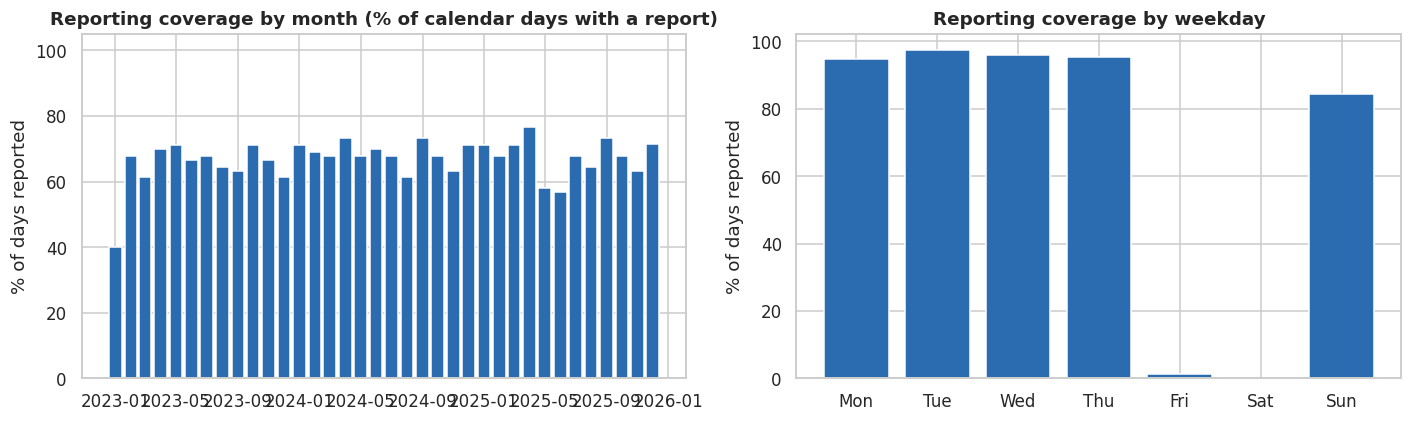

In [6]:
# Which days are missing? Mostly weekends.
missing = daily.loc[~daily["reported"]]
print("Missing days by weekday:")
print(missing.index.day_name().value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]).fillna(0).astype(int))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
cov = daily["reported"].resample("MS").mean() * 100
ax[0].bar(cov.index, cov.values, width=25, color="#2b6cb0")
ax[0].set_title("Reporting coverage by month (% of calendar days with a report)")
ax[0].set_ylim(0, 105); ax[0].set_ylabel("% of days reported")
wd = daily.groupby(daily.index.dayofweek)["reported"].mean() * 100
ax[1].bar(["Mon","Tue","Wed","Thu","Fri","Sat","Sun"], wd.values, color="#2b6cb0")
ax[1].set_title("Reporting coverage by weekday"); ax[1].set_ylabel("% of days reported")
save(fig, "01_reporting_coverage")

In [7]:
# Logical-constraint violations (flagged, NOT deleted, for transparency)
viol = daily.loc[daily["flag_transfer_gt_cbp"],
                 ["cbp_custody","transferred","hhs_care","discharged"]]
print(f"Days where Transfers > CBP custody: {len(viol)}  ({100*len(viol)/daily['reported'].sum():.1f}% of reported days)")
print("By year:", viol.index.year.value_counts().sort_index().to_dict())
print("Days where Discharges > HHS care:", int(daily['flag_discharge_gt_hhs'].sum()))
viol.head(10)

Days where Transfers > CBP custody: 86  (11.9% of reported days)
By year: {2023: 43, 2024: 31, 2025: 12}
Days where Discharges > HHS care: 0


,cbp_custody,transferred,hhs_care,discharged
date,,,,
2023-01-24,42.0,47.0,7433.0,175.0
2023-01-25,22.0,41.0,7538.0,180.0
2023-02-02,13.0,23.0,7879.0,298.0
2023-02-22,215.0,230.0,7978.0,232.0
2023-02-23,162.0,178.0,7914.0,386.0
2023-03-01,158.0,193.0,7930.0,307.0
2023-04-03,139.0,168.0,8054.0,284.0
2023-04-25,230.0,242.0,8017.0,202.0
2023-05-04,253.0,286.0,8790.0,332.0


> **Interpretation.** Transfers exceeding the end-of-day CBP custody count is plausible and is *not* necessarily a data error: custody is a **snapshot** taken at the end of the day, while transfers happen during the day (children apprehended and transferred the same day never appear in the closing count). We therefore flag these days as *soft anomalies* rather than removing them. The discharge constraint is never violated.

In [8]:
rec = reconciliation(daily)
print(f"Consecutive-day pairs compared : {rec['pairs_compared']}")
print(f"Correlation  ΔHHS census vs (transfers - discharges): {rec['correlation']:.2f}")
print(f"Mean daily ΔHHS census          : {rec['mean_census_change']:+.1f}")
print(f"Mean daily (transfers-discharges): {rec['mean_net_flow']:+.1f}")

Consecutive-day pairs compared : 558
Correlation  ΔHHS census vs (transfers - discharges): 0.22
Mean daily ΔHHS census          : +30.3
Mean daily (transfers-discharges): -37.4


> **Important caveat.** The HHS census does **not** reconcile tightly with `transfers − discharges` (low correlation, and the averages even differ in sign). HHS also receives children from sources other than CBP transfers, so *Net Daily Intake* is best read as a **pressure proxy from the CBP→HHS pipeline**, not an exact census change. We keep it because the project brief defines it this way, but all conclusions about the *level* of care load use the observed census counts directly.

**Handling of missing days:** census counts (CBP custody, HHS care) are linearly interpolated across gaps so that daily totals and rolling windows are continuous. Daily *flows* (apprehended / transferred / discharged) are **never** invented — they stay blank on unreported days, and weekly/monthly views use the *average per reported day* so periods with different reporting coverage stay comparable.

## 3. Derived healthcare capacity metrics

In [9]:
daily = compute_metrics(daily, strain_pct=75)
daily[["total_load","net_intake","growth_rate","net_ma7","net_ma14","load_ma7","load_ma14",
       "backlog_sustained","strain_window","status"]].dropna().head(10)

,total_load,net_intake,growth_rate,net_ma7,net_ma14,load_ma7,load_ma14,backlog_sustained,strain_window,status
date,,,,,,,,,,
2023-01-23,7330.0,-142.0,2.217264,-165.000000,-244.000000,7075.428571,6931.250000,False,False,Stable
2023-01-24,7475.0,-128.0,1.978172,-152.666667,-215.000000,7158.285714,6973.076923,False,False,Stable
2023-01-25,7560.0,-139.0,1.137124,-149.250000,-199.800000,7245.400000,7015.000000,False,False,Stable
2023-01-29,7517.0,-292.0,-0.142805,-175.250000,-177.800000,7499.642857,7252.521429,False,False,Stable
2023-01-30,7797.0,-167.0,3.724890,-181.500000,-176.000000,7566.357143,7320.892857,False,False,Stable
2023-01-31,7839.0,-122.0,0.538669,-180.000000,-168.285714,7618.357143,7388.321429,False,False,Stable
2023-02-01,7935.0,-204.0,1.224646,-196.250000,-172.750000,7671.928571,7458.664286,False,False,Stable
2023-02-02,7892.0,-275.0,-0.541903,-212.000000,-184.111111,7720.892857,7521.992857,False,False,Stable
2023-02-05,7604.0,-327.0,-1.246753,-219.000000,-199.555556,7794.714286,7647.178571,False,False,Stable


In [10]:
daily[["total_load","net_intake","growth_rate","cbp_custody","hhs_care"]].describe().round(1)

,total_load,net_intake,growth_rate,cbp_custody,hhs_care
count,1075.0,720.0,1074.0,1075.0,1075.0
mean,6231.8,-44.7,-0.1,169.1,6062.7
std,2911.6,95.9,1.1,125.3,2827.0
min,2002.0,-465.0,-4.2,7.0,1972.0
25%,2512.4,-94.2,-0.7,35.0,2480.5
50%,6635.0,-11.5,-0.1,188.0,6410.0
75%,8247.5,5.2,0.5,259.2,8006.0
max,11762.0,206.0,4.7,531.0,11516.0


## 4. Trend & temporal analysis
### 4.1 System load overview — CBP vs HHS

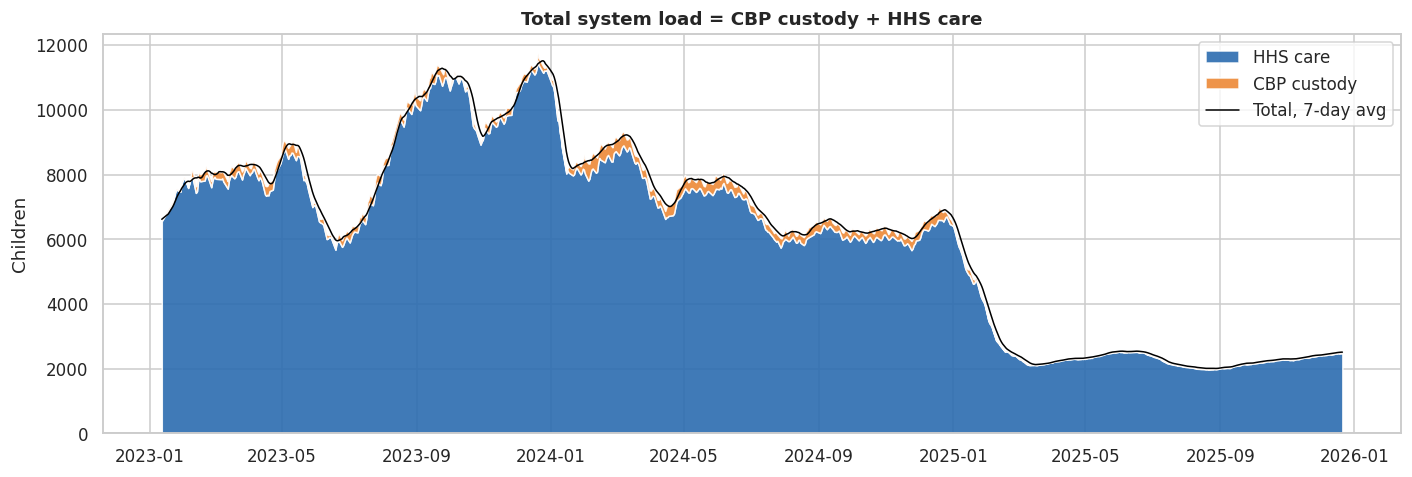

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.stackplot(daily.index, daily["hhs_care"], daily["cbp_custody"],
             labels=["HHS care", "CBP custody"], colors=["#2b6cb0", "#ed8936"], alpha=.9)
ax.plot(daily.index, daily["load_ma7"], color="black", lw=1, label="Total, 7-day avg")
ax.set_title("Total system load = CBP custody + HHS care")
ax.set_ylabel("Children"); ax.legend(loc="upper right")
save(fig, "02_total_system_load")

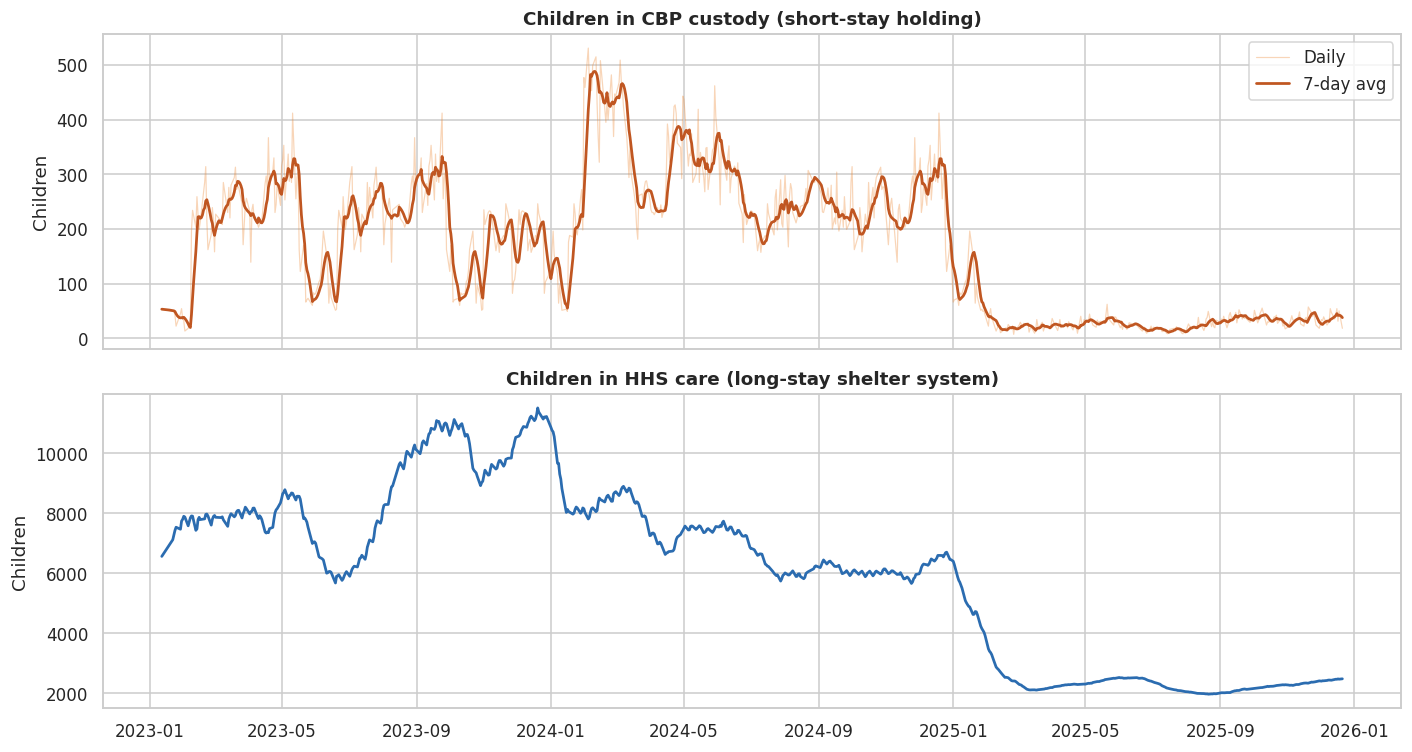

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax[0].plot(daily.index, daily["cbp_custody"], color="#ed8936", alpha=.35, lw=.8, label="Daily")
ax[0].plot(daily.index, daily["cbp_custody"].rolling(7, min_periods=1).mean(), color="#c05621", lw=1.8, label="7-day avg")
ax[0].set_title("Children in CBP custody (short-stay holding)"); ax[0].legend()
ax[1].plot(daily.index, daily["hhs_care"], color="#2b6cb0", lw=1.8)
ax[1].set_title("Children in HHS care (long-stay shelter system)")
for a in ax: a.set_ylabel("Children")
save(fig, "03_cbp_vs_hhs")

### 4.2 Flows: intake, transfers and discharges (weekly average per reported day)

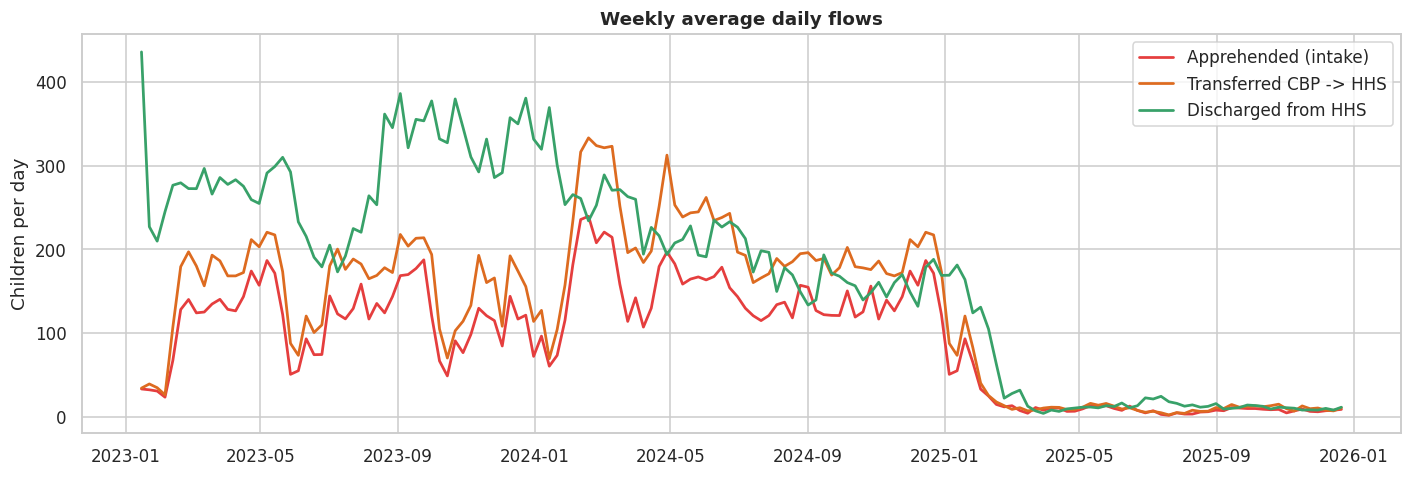

In [13]:
wk = aggregate(daily, "W")
fig, ax = plt.subplots(figsize=(13, 4.5))
for c, col in [("apprehended","#e53e3e"),("transferred","#dd6b20"),("discharged","#38a169")]:
    ax.plot(wk.index, wk[c], label=LABELS[c], color=col, lw=1.8)
ax.set_title("Weekly average daily flows"); ax.set_ylabel("Children per day"); ax.legend()
save(fig, "04_weekly_flows")

### 4.3 Daily, weekly & monthly trends

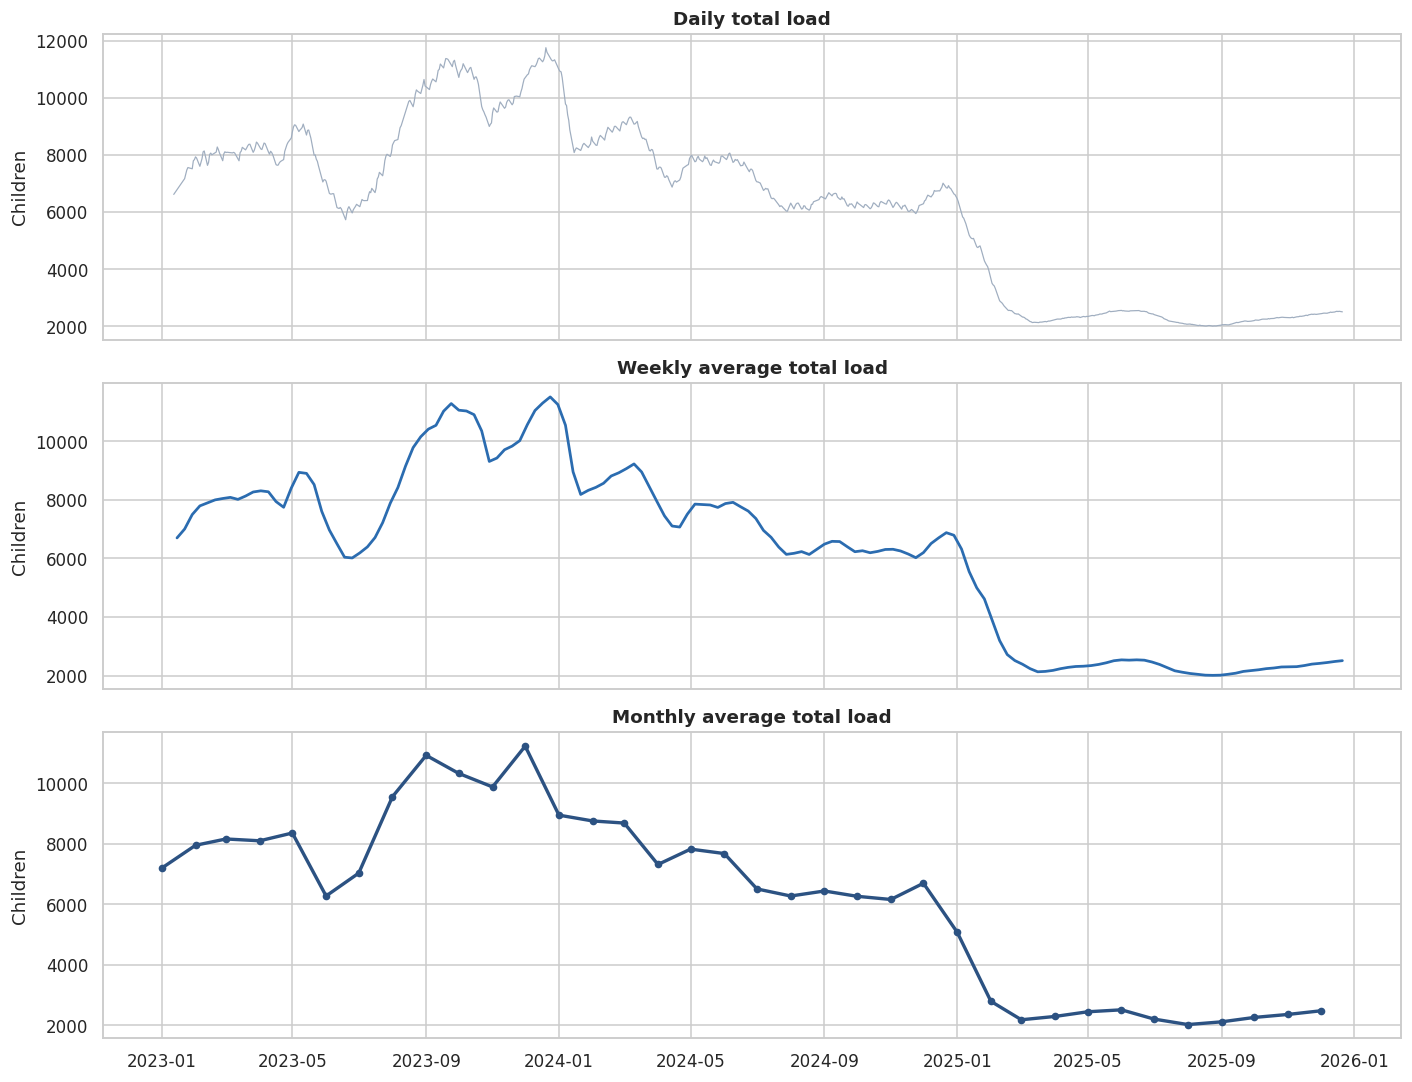

In [14]:
mo = aggregate(daily, "MS")
fig, ax = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
ax[0].plot(daily.index, daily["total_load"], color="#a0aec0", lw=.8); ax[0].set_title("Daily total load")
ax[1].plot(wk.index, wk["total_load"], color="#2b6cb0", lw=1.8);       ax[1].set_title("Weekly average total load")
ax[2].plot(mo.index, mo["total_load"], color="#2c5282", lw=2.2, marker="o", ms=4); ax[2].set_title("Monthly average total load")
for a in ax: a.set_ylabel("Children")
save(fig, "05_granularity_trends")

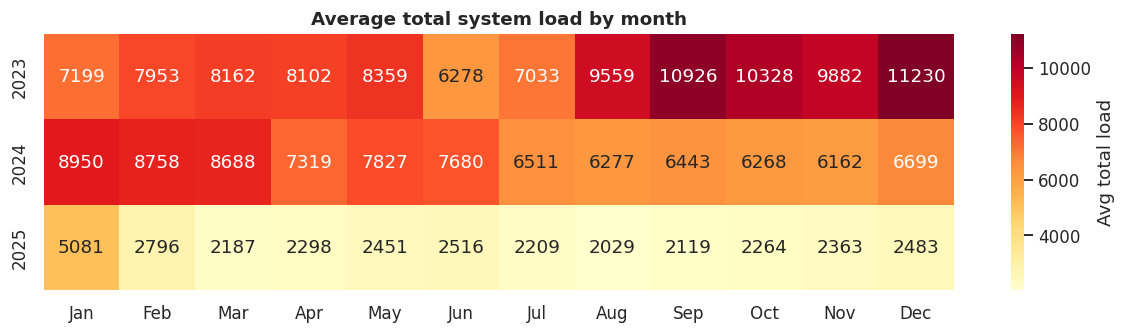

In [15]:
heat = daily.groupby([daily.index.year, daily.index.month])["total_load"].mean().unstack()
heat.columns = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"][:heat.shape[1]]
fig, ax = plt.subplots(figsize=(11, 3.2))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd", cbar_kws={"label": "Avg total load"}, ax=ax)
ax.set_title("Average total system load by month"); ax.set_ylabel("")
save(fig, "06_monthly_heatmap")

### 4.4 Early vs late timeline & calendar-period comparison

In [16]:
def kpi_frame(frames):
    t = pd.DataFrame({n: compute_kpis(f) for n, f in frames.items()}).T
    t = t[["total_latest","total_avg","peak_total","net_pressure","clvi","backlog_rate","backlog_share","buildup_share","dor"]]
    t.columns = ["Latest total load","Avg total load","Peak total load","Net intake pressure (avg/day)",
                 "Volatility index (%)","Backlog accum. rate (/day)","% days in backlog","% days census build-up","Discharge offset ratio"]
    return t.astype(float).round(2)

mid = daily.index[0] + (daily.index[-1] - daily.index[0]) / 2
periods = {
    "Early half": daily[daily.index <= mid],
    "Late half":  daily[daily.index > mid],
    **{str(y): daily[daily.index.year == y] for y in sorted(set(daily.index.year))},
}
print(f"Early/late split date: {mid:%Y-%m-%d}")
period_table = kpi_frame(periods)
period_table

Early/late split date: 2024-07-02


,Latest total load,Avg total load,Peak total load,Net intake pressure (avg/day),Volatility index (%),Backlog accum. rate (/day),% days in backlog,% days census build-up,Discharge offset ratio
Early half,7055.00,8595.82,11762.0,-88.33,1.30,48.12,18.03,51.86,1.48
Late half,2502.00,3863.30,7035.5,-1.39,0.91,20.09,43.20,51.02,1.02
2023,11079.75,8805.36,11762.0,-130.96,1.33,0.00,0.00,58.47,1.83
2024,6540.50,7294.77,10994.0,3.44,1.07,38.20,64.21,43.44,0.98
2025,2502.00,2569.46,6471.0,-12.36,0.90,3.82,26.48,52.68,1.75


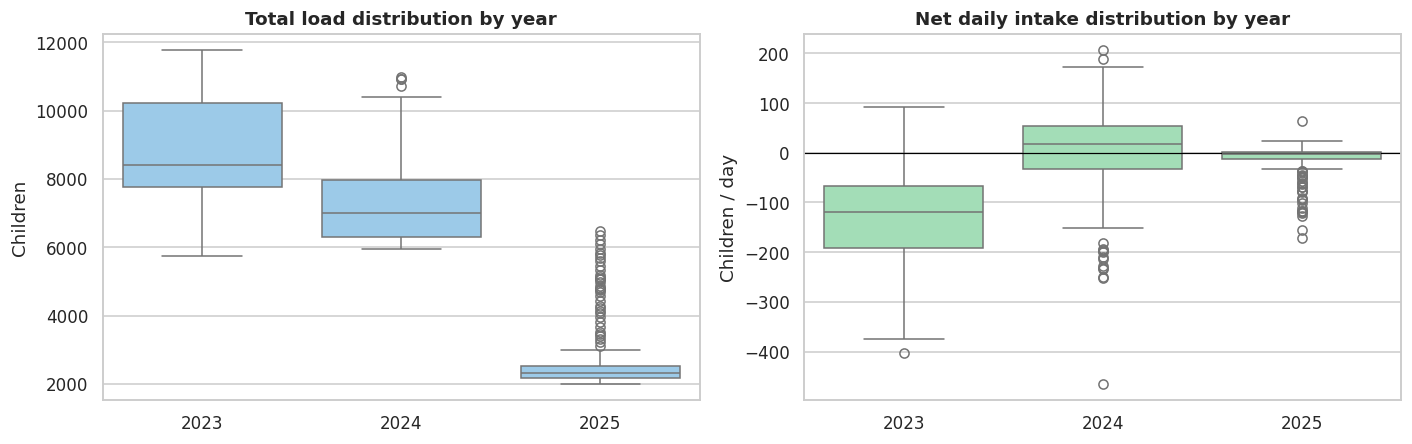

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.boxplot(x=daily.index.year, y=daily["total_load"], ax=ax[0], color="#90cdf4")
ax[0].set_title("Total load distribution by year"); ax[0].set_xlabel(""); ax[0].set_ylabel("Children")
sns.boxplot(x=daily.index.year, y=daily["net_intake"], ax=ax[1], color="#9ae6b4")
ax[1].axhline(0, color="black", lw=.8)
ax[1].set_title("Net daily intake distribution by year"); ax[1].set_xlabel(""); ax[1].set_ylabel("Children / day")
save(fig, "07_yearly_boxplots")

### 4.5 Extra exploration: day-of-week pattern, correlations and pipeline lag

Reports per weekday: {'Mon': 145, 'Tue': 149, 'Wed': 147, 'Thu': 147, 'Fri': 2, 'Sun': 130}
-> Fridays (n=2) and Saturdays (n=0) are almost never reported, so they are excluded from the weekday comparison.


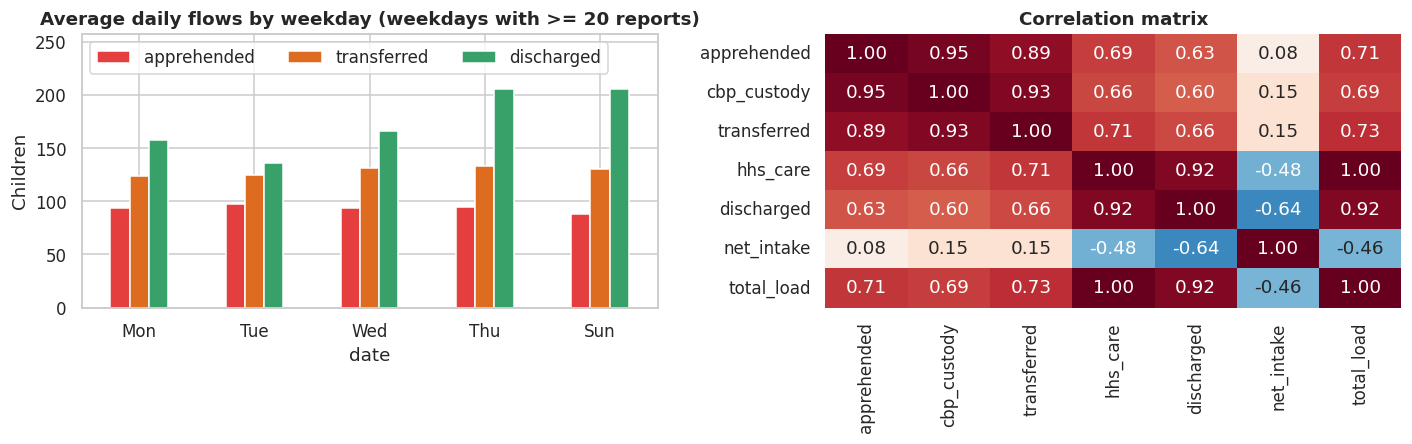

In [18]:
rep = daily[daily["reported"]].copy()
n_by_dow = rep.groupby(rep.index.dayofweek).size()
keep = n_by_dow[n_by_dow >= 20].index          # weekdays with enough reports to compare
names = {0:"Mon",1:"Tue",2:"Wed",3:"Thu",4:"Fri",5:"Sat",6:"Sun"}
print("Reports per weekday:", {names[i]: int(v) for i, v in n_by_dow.items()})
print("-> Fridays (n=2) and Saturdays (n=0) are almost never reported, so they are excluded from the weekday comparison.")
sub = rep[rep.index.dayofweek.isin(keep)]
dow = sub.groupby(sub.index.dayofweek)[["apprehended","transferred","discharged"]].mean()
dow.index = dow.index.map(names)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
dow.plot(kind="bar", ax=ax[0], color=["#e53e3e","#dd6b20","#38a169"], rot=0)
ax[0].set_title("Average daily flows by weekday (weekdays with >= 20 reports)"); ax[0].set_ylabel("Children")
ax[0].set_ylim(0, dow.values.max() * 1.25); ax[0].legend(ncol=3, loc="upper left")
corr = rep[["apprehended","cbp_custody","transferred","hhs_care","discharged","net_intake","total_load"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1], cbar=False)
ax[1].set_title("Correlation matrix")
save(fig, "08_weekday_and_correlation")

In [19]:
# Pipeline lag: how many days after apprehension do transfers to HHS peak?
lags = range(0, 8)
lag_corr = pd.Series({k: daily["apprehended"].corr(daily["transferred"].shift(-k)) for k in lags})
print("Correlation of apprehensions with transfers k days later:")
print(lag_corr.round(3).to_string())
print(f"\nStrongest alignment at lag = {lag_corr.idxmax()} day(s)")

Correlation of apprehensions with transfers k days later:
0    0.888
1    0.928
2    0.875
3    0.846
4    0.875
5    0.867
6    0.844
7    0.818

Strongest alignment at lag = 1 day(s)


## 5. Pressure & stress identification
### 5.1 Net intake, backlog indicator and rolling averages (7-day and 14-day)

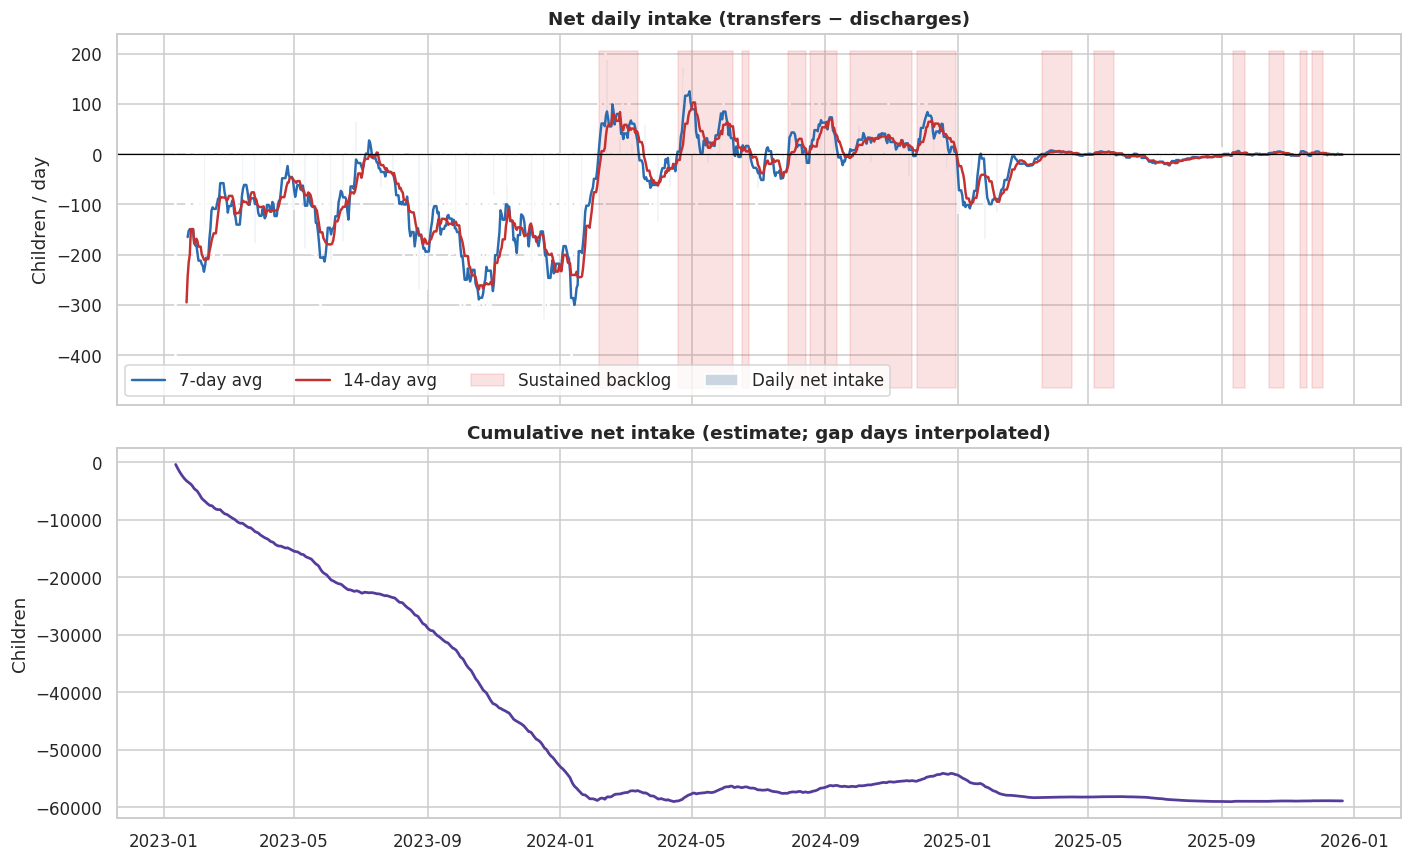

In [20]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
ax[0].bar(daily.index, daily["net_intake"], color="#cbd5e0", width=1.0, label="Daily net intake")
ax[0].plot(daily.index, daily["net_ma7"],  color="#2b6cb0", lw=1.6, label="7-day avg")
ax[0].plot(daily.index, daily["net_ma14"], color="#c53030", lw=1.6, label="14-day avg")
ax[0].fill_between(daily.index, daily["net_intake"].min(), daily["net_intake"].max(),
                   where=daily["backlog_sustained"], color="#e53e3e", alpha=.15, label="Sustained backlog")
ax[0].axhline(0, color="black", lw=.8)
ax[0].set_title("Net daily intake (transfers − discharges)"); ax[0].set_ylabel("Children / day"); ax[0].legend(ncol=4, loc="lower left")
ax[1].plot(daily.index, daily["cum_net_intake"], color="#553c9a", lw=1.8)
ax[1].set_title("Cumulative net intake (estimate; gap days interpolated)"); ax[1].set_ylabel("Children")
save(fig, "09_net_intake_backlog")

In [21]:
print("Sustained backlog periods (7-day avg net intake > 0 for >= 7 consecutive days):")
backlog_windows = list_windows(daily, "backlog_sustained")
backlog_windows

Sustained backlog periods (7-day avg net intake > 0 for >= 7 consecutive days):


,start,end,days,avg_total_load,peak_total_load,avg_net_intake
0,2024-02-06,2024-03-13,37,8953,9327,53.7
1,2024-04-18,2024-06-08,52,7742,8067,52.5
2,2024-06-16,2024-06-23,8,7618,7754,-1.8
3,2024-07-29,2024-08-14,17,6202,6314,22.4
4,2024-08-18,2024-09-12,26,6475,6678,43.9
5,2024-09-24,2024-11-20,58,6236,6425,24.9
6,2024-11-24,2024-12-30,37,6599,7012,36.8
7,2025-03-19,2025-04-16,29,2229,2321,4.2
8,2025-05-06,2025-05-25,20,2449,2529,3.6
9,2025-09-11,2025-09-22,12,2135,2181,4.6


**Supplementary check — census-based build-up.** Because Net Daily Intake does not reconcile with the census (Section 2), we add a second indicator: days where the 7-day average *change in HHS census* is positive for ≥ 7 consecutive days. It captures real caseload growth that the transfers − discharges metric can miss.

,pct_days_sustained_net_intake_backlog,pct_days_census_buildup,avg_net_intake,avg_census_change_per_day
date,,,,
2023,0.0,58.5,-131.0,12.4
2024,64.2,43.4,3.4,-12.4
2025,26.5,52.7,-12.4,-11.1


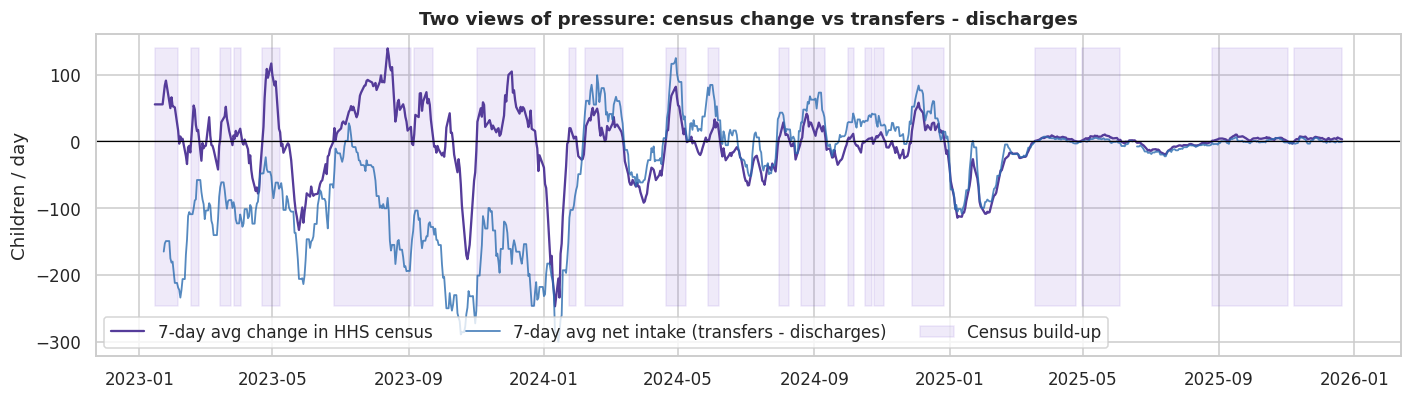

In [22]:
buildup = daily.groupby(daily.index.year).agg(
    pct_days_sustained_net_intake_backlog=("backlog_sustained", lambda x: 100*x.mean()),
    pct_days_census_buildup=("census_buildup", lambda x: 100*x.mean()),
    avg_net_intake=("net_intake", "mean"),
    avg_census_change_per_day=("census_change", "mean"),
).round(1)
display(buildup)

fig, ax = plt.subplots(figsize=(13, 3.8))
ax.plot(daily.index, daily["census_ma7"], color="#553c9a", lw=1.5, label="7-day avg change in HHS census")
ax.plot(daily.index, daily["net_ma7"], color="#2b6cb0", lw=1.2, alpha=.8, label="7-day avg net intake (transfers - discharges)")
ax.fill_between(daily.index, daily["census_ma7"].min(), daily["census_ma7"].max(), where=daily["census_buildup"],
                color="#805ad5", alpha=.12, label="Census build-up")
ax.axhline(0, color="black", lw=.8); ax.set_ylabel("Children / day"); ax.legend(ncol=3, loc="lower left")
ax.set_title("Two views of pressure: census change vs transfers - discharges")
save(fig, "09b_census_vs_net_intake")

### 5.2 Variability analysis

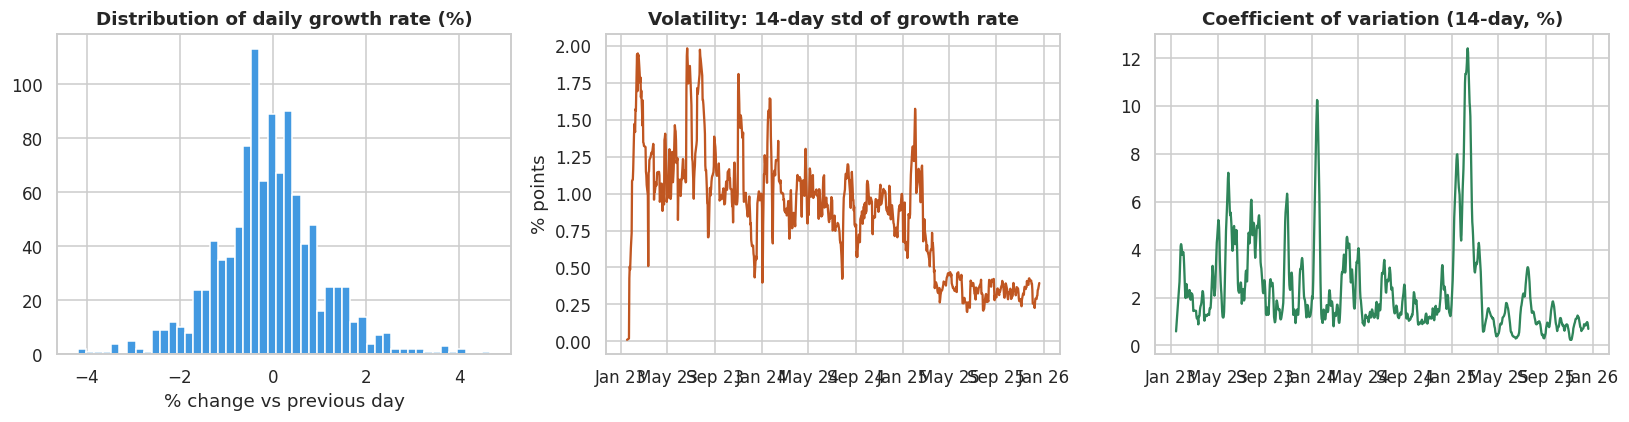

Daily growth-rate outliers flagged (robust MAD z>3.5): 20


,total_load,growth_rate
date,,
2023-01-30,7797.0,3.72
2023-02-14,8019.0,3.58
2023-02-27,8039.0,3.08
2023-03-14,8086.0,3.71
2023-04-24,8126.0,3.65
2023-06-20,5957.0,3.96
2023-07-18,7159.0,4.66
2023-07-24,7500.0,3.14
2023-07-25,7804.0,4.05


In [23]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(daily["growth_rate"].dropna(), bins=50, color="#4299e1", edgecolor="white")
ax[0].set_title("Distribution of daily growth rate (%)"); ax[0].set_xlabel("% change vs previous day")
ax[1].plot(daily.index, daily["growth_std14"], color="#c05621")
ax[1].set_title("Volatility: 14-day std of growth rate"); ax[1].set_ylabel("% points")
ax[2].plot(daily.index, daily["load_cv14"], color="#2f855a")
ax[2].set_title("Coefficient of variation (14-day, %)")
for a in ax[1:]: a.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
save(fig, "10_variability")
print("Daily growth-rate outliers flagged (robust MAD z>3.5):", int(daily["flag_growth_outlier"].sum()))
daily.loc[daily["flag_growth_outlier"], ["total_load","growth_rate"]].round(2).head(10)

### 5.3 Prolonged strain windows and relief periods
*Strain* = 14-day average load stays at/above the 75th-percentile of the whole period for ≥ 14 days. *Relief* = load is falling week-over-week for ≥ 7 days. (Both thresholds are parameters of `compute_metrics`.)

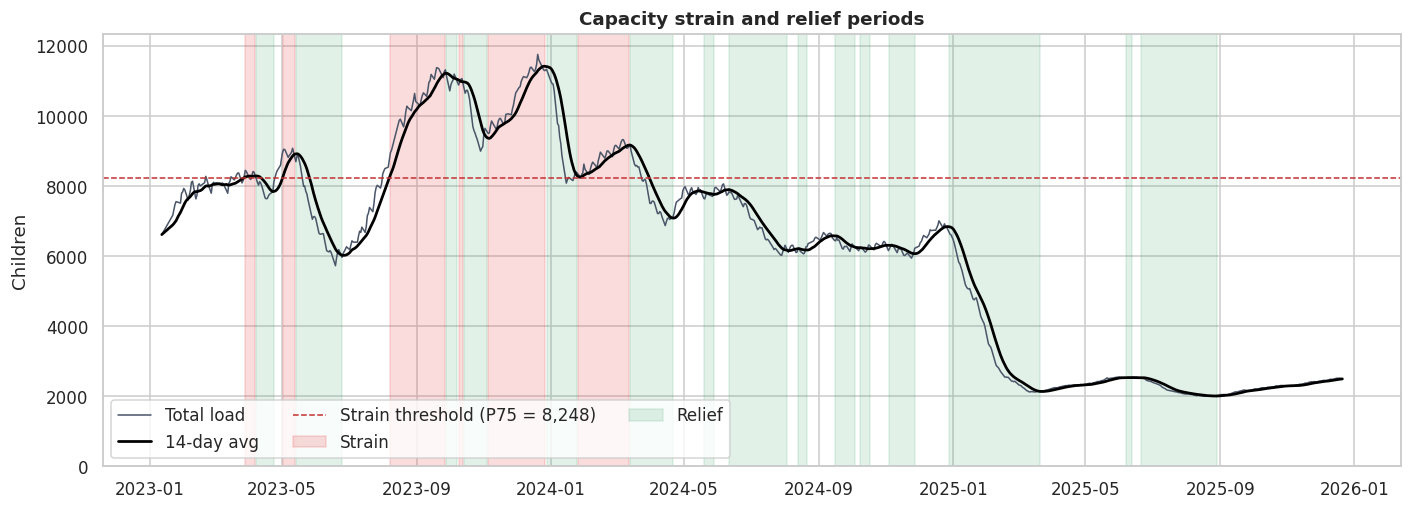

status
Relief    450
Stable    447
Strain    178


In [24]:
fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(daily.index, daily["total_load"], color="#4a5568", lw=1, label="Total load")
ax.plot(daily.index, daily["load_ma14"], color="black", lw=1.8, label="14-day avg")
ax.axhline(daily["strain_threshold"].iloc[0], color="#c53030", ls="--", lw=1,
           label=f"Strain threshold (P75 = {daily['strain_threshold'].iloc[0]:,.0f})")
ymax = daily["total_load"].max() * 1.05
ax.fill_between(daily.index, 0, ymax, where=(daily["status"] == "Strain"), color="#e53e3e", alpha=.18, label="Strain")
ax.fill_between(daily.index, 0, ymax, where=(daily["status"] == "Relief"), color="#38a169", alpha=.15, label="Relief")
ax.set_ylim(0, ymax); ax.set_title("Capacity strain and relief periods"); ax.set_ylabel("Children"); ax.legend(ncol=3, loc="lower left")
save(fig, "11_strain_relief")
print(daily["status"].value_counts().to_string())

In [25]:
print("Prolonged strain windows:")
strain_windows = list_windows(daily, "strain_window")
strain_windows

Prolonged strain windows:


,start,end,days,avg_total_load,peak_total_load,avg_net_intake
0,2023-03-29,2023-04-11,14,8271,8453,-111.5
1,2023-05-02,2023-05-26,25,8579,9084,-121.2
2,2023-08-08,2024-03-30,236,9841,11762,-127.4


## 6. Key Performance Indicators

In [26]:
k = compute_kpis(daily)
kpi_cards = pd.DataFrame({
    "KPI": ["Total Children Under Care (latest)", "Total Children Under Care (period avg)", "Peak total load",
            "Net Intake Pressure (avg children/day)", "Care Load Volatility Index (% pts)",
            "Backlog Accumulation Rate (children/day in backlog)", "Share of days in sustained backlog (%)",
            "Discharge Offset Ratio"],
    "Value": [f"{k['total_latest']:,.0f}", f"{k['total_avg']:,.0f}", f"{k['peak_total']:,.0f} ({k['peak_date']:%d %b %Y})",
              f"{k['net_pressure']:+.1f}", f"{k['clvi']:.2f}", f"{k['backlog_rate']:+.1f}",
              f"{k['backlog_share']:.1f}", f"{k['dor']:.2f}"],
    "How to read it": [
        "System-wide responsibility on the last reporting day",
        "Typical load across the selected period",
        "Highest combined CBP + HHS load observed",
        "Negative = more discharges than transfers (load easing)",
        "Higher = less stable day-to-day load",
        "How fast the queue grows when pressure is sustained",
        "How often the system is in a sustained build-up",
        ">1 means discharges outpace new transfers (system can relieve load)"],
})
kpi_cards

,KPI,Value,How to read it
0,Total Children Under Care (latest),"2,502",System-wide responsibility on the last reporti...
1,Total Children Under Care (period avg),"6,232",Typical load across the selected period
2,Peak total load,"11,762 (20 Dec 2023)",Highest combined CBP + HHS load observed
3,Net Intake Pressure (avg children/day),-44.7,Negative = more discharges than transfers (loa...
4,Care Load Volatility Index (% pts),1.13,Higher = less stable day-to-day load
5,Backlog Accumulation Rate (children/day in bac...,+28.3,How fast the queue grows when pressure is sust...
6,Share of days in sustained backlog (%),30.6,How often the system is in a sustained build-up
7,Discharge Offset Ratio,1.35,>1 means discharges outpace new transfers (sys...


In [27]:
period_table

,Latest total load,Avg total load,Peak total load,Net intake pressure (avg/day),Volatility index (%),Backlog accum. rate (/day),% days in backlog,% days census build-up,Discharge offset ratio
Early half,7055.00,8595.82,11762.0,-88.33,1.30,48.12,18.03,51.86,1.48
Late half,2502.00,3863.30,7035.5,-1.39,0.91,20.09,43.20,51.02,1.02
2023,11079.75,8805.36,11762.0,-130.96,1.33,0.00,0.00,58.47,1.83
2024,6540.50,7294.77,10994.0,3.44,1.07,38.20,64.21,43.44,0.98
2025,2502.00,2569.46,6471.0,-12.36,0.90,3.82,26.48,52.68,1.75


## 7. Insights, recommendations & export

In [28]:
y = {str(yr): compute_kpis(daily[daily.index.year == yr]) for yr in sorted(set(daily.index.year))}
peak_day = daily["total_load"].idxmax()
first, last = daily["total_load"].iloc[0], daily["total_load"].iloc[-1]
sw = list_windows(daily, "strain_window")

print("KEY FINDINGS (auto-generated from the data)")
print("-" * 60)
print(f"1. Load fell {100*(1-last/first):.0f}% over the study period: {first:,.0f} children on {daily.index[0]:%d %b %Y} -> {last:,.0f} on {daily.index[-1]:%d %b %Y}.")
print(f"2. Peak system load was {daily['total_load'].max():,.0f} children on {peak_day:%d %b %Y}.")
print(f"3. {int(daily['strain_window'].sum())} calendar days ({100*daily['strain_window'].mean():.0f}%) sat in prolonged-strain windows; longest = {sw['days'].max() if len(sw) else 0} days.")
print(f"4. Discharge Offset Ratio by year: " + ", ".join(f"{yr}: {v['dor']:.2f}" for yr, v in y.items()))
print(f"5. Average net intake by year: " + ", ".join(f"{yr}: {v['net_pressure']:+.1f}/day" for yr, v in y.items()))
print(f"6. Volatility index by year: " + ", ".join(f"{yr}: {v['clvi']:.2f}" for yr, v in y.items()))
print(f"7. {int(daily['flag_transfer_gt_cbp'].sum())} reported days had transfers > end-of-day CBP custody (flagged, kept).")
print("8. Census change vs cumulative net intake by year (reconciliation check):")
for yr in sorted(set(daily.index.year)):
    sub = daily[daily.index.year == yr]
    print(f"   {yr}: HHS census {sub['hhs_care'].iloc[0]:,.0f} -> {sub['hhs_care'].iloc[-1]:,.0f} "
          f"({sub['hhs_care'].iloc[-1]-sub['hhs_care'].iloc[0]:+,.0f}) | cumulative (transfers - discharges) = {sub['net_intake_est'].sum():+,.0f}")
print(f"   -> The brief's net-intake backlog flag shows {y['2023']['backlog_share']:.0f}% of 2023 days in backlog, yet the census-based build-up flag shows {y['2023']['buildup_share']:.0f}%: use both.")
print(f"9. Discharges track census size (corr discharged vs total load = {daily['discharged'].corr(daily['total_load']):.2f}): bigger caseloads are discharged faster.")
print(f"10. Apprehensions -> transfers are most aligned at a {lag_corr.idxmax()}-day lag (r = {lag_corr.max():.2f}): CBP intake is a ~1-day leading indicator for HHS inflow.")

KEY FINDINGS (auto-generated from the data)
------------------------------------------------------------
1. Load fell 62% over the study period: 6,619 children on 12 Jan 2023 -> 2,502 on 21 Dec 2025.
2. Peak system load was 11,762 children on 20 Dec 2023.
3. 275 calendar days (26%) sat in prolonged-strain windows; longest = 236 days.
4. Discharge Offset Ratio by year: 2023: 1.83, 2024: 0.98, 2025: 1.75
5. Average net intake by year: 2023: -131.0/day, 2024: +3.4/day, 2025: -12.4/day
6. Volatility index by year: 2023: 1.33, 2024: 1.07, 2025: 0.90
7. 86 reported days had transfers > end-of-day CBP custody (flagged, kept).
8. Census change vs cumulative net intake by year (reconciliation check):
   2023: HHS census 6,566 -> 10,960 (+4,394) | cumulative (transfers - discharges) = -52,707
   2024: HHS census 10,870 -> 6,430 (-4,440) | cumulative (transfers - discharges) = -1,623
   2025: HHS census 6,405 -> 2,484 (-3,921) | cumulative (transfers - discharges) = -4,540
   -> The brief's net-i

### Recommendations (to include in the research paper)
1. **Plan staffing and beds to the strain threshold, not the average.** Use the 75th-percentile load (shown on the strain chart) as the trigger for surge capacity; the system spent long continuous stretches above it (the longest ran for several months).
2. **Use CBP intake as a ~1-day leading indicator.** Apprehensions and transfers to HHS are most strongly aligned at a one-day lag, so same-day CBP numbers give HHS roughly a day of warning.
3. **Track HHS census change directly, not only transfers − discharges.** Net Daily Intake (as defined in the brief) does not reconcile with the actual census change, so it should be paired with the daily census delta when judging whether load is building or easing.
4. **Protect discharge throughput.** Discharges scale with caseload size (corr ≈ 0.92 with total load) and the Discharge Offset Ratio shows when the system can actually drain; sponsor-vetting and placement capacity are the main relief valve.
5. **Fix reporting gaps.** About a third of calendar days have no report, and several days show transfers larger than end-of-day custody. Publishing a daily census plus every inflow source (not only CBP transfers) would make capacity monitoring more reliable.
6. **Plan around the reporting cadence.** Reports follow a Sunday–Thursday pattern (Fridays and Saturdays are almost never reported), so weekly rotas and week-over-week comparisons should be built on that cadence; among reported days, discharges are highest on Thursdays and Sundays.

In [29]:
# Export the processed dataset (useful for the paper appendix / Tableau / Excel)
export_cols = ["reported","apprehended","cbp_custody","transferred","hhs_care","discharged","total_load",
               "net_intake","growth_rate","load_ma7","load_ma14","net_ma7","net_ma14","cum_net_intake",
               "backlog_sustained","strain_window","relief_window","status",
               "flag_transfer_gt_cbp","flag_discharge_gt_hhs","flag_growth_outlier"]
daily[export_cols].to_csv("uac_daily_processed.csv")
period_table.to_csv("uac_kpis_by_period.csv")
print("Saved: uac_daily_processed.csv, uac_kpis_by_period.csv and PNG charts in ./figures/")

Saved: uac_daily_processed.csv, uac_kpis_by_period.csv and PNG charts in ./figures/
